<a href="https://colab.research.google.com/github/edsonportosilva/OpticalCommunications/blob/main/jupyter%20notebooks/English/4.%20Optical%20fiber_dispersion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
if 'google.colab' in str(get_ipython()):    
    ! git clone -b main https://github.com/edsonportosilva/OptiCommPy
    from os import chdir as cd
    cd('/content/OptiCommPy/')
    ! pip install .
    cd('/content/')
    ! wget https://raw.githubusercontent.com/edsonportosilva/OpticalCommunications/main/jupyter%20notebooks/English/utils.py

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Pulses" data-toc-modified-id="Pulses-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Pulses</a></span><ul class="toc-item"><li><span><a href="#Gaussian-Pulse" data-toc-modified-id="Gaussian-Pulse-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>Gaussian-Pulse</a></span></li><li><span><a href="#Super-Gaussian-Pulse" data-toc-modified-id="Super-Gaussian-Pulse-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Super Gaussian Pulse</a></span></li></ul></li><li><span><a href="#Basic-Propagation-Equation" data-toc-modified-id="Basic-Propagation-Equation-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Basic propagation equation</a></span><ul class="toc-item"><li><span><a href="#Chirped-Gaussian-pulse" data-toc-modified-id="Chirped-Gaussian-Pulse"----chirped-Gaussian-pulse-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Chirped Gaussian Pulse -<em>chirped Gaussian pulse</em></a></span></li><li><span><a href="#10G-OOK-Transmission-only-with-dispersion" data-toc-modified-id="10G-OOK-Transmission-only-with-dispersion-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>10G OOK Transmission only with dispersion</a></span></li></ul></li></ul></div>

In [2]:
from optic.utils import parameters
from IPython.core.display import HTML
from IPython.core.pylabtools import figsize
from IPython.display import display, Math

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

In [3]:
import numpy as np
import scipy.special as sp
from  scipy.constants import c
import matplotlib.pyplot as plt
from optic.dsp.core import firFilter, pulseShape, lowPassFIR
from optic.plot import eyediagram
from optic.comm.metrics import signalPower
from commpy.utilities  import upsample
from optic.models.devices import mzm

In [4]:
SMALL_SIZE = 14
MEDIUM_SIZE = 14
BIGGER_SIZE = 14

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# Pulses

## Gaussian Pulse

As an application example, consider that the pulse has a Gaussian shape:
\begin{equation}
A\left( 0,t \right) = A_0e^{-\frac{1}{2}\left( \frac{t}{T_0} \right)^2},
\end{equation}
where $A_0$ is the peak amplitude and $T_0$ is half the $1/e$ width of the intensity point (or 1.665$T_0$ width at half height - FWHM - *full width at half maximum*). The Fourier transform of the pulse is
\begin{equation}
\widetilde{A} \left( 0, \omega \right) = A_0 T_0 \sqrt{2 \pi} e^{\left[-\frac{1}{2}\left( w T_0 \right)^2\right]}
\end{equation}

In [5]:
#Khai báo hàm biểu diễn xung và biến đổi Fourier
def GaussPulse(a0, t0, t):     # Định nghĩa hàm tạo xung Gaussian trong miền thời gian
  return a0*np.exp(-0.5*(t/t0)**2) # Tính giá trị A(0,t) = a0 * exp(-0.5 * (t/t0)^2)
def FGaussPulse(a0, t0, freq):  # # Định nghĩa hàm phổ Gaussian lý thuyết (giải tích) trong miền tần số
  return a0*t0*np.sqrt(2*np.pi)*np.exp(-0.5*(2*np.pi*freq*t0)**2) # Tính giá trị A(0,f) = a0 * t0 * sqrt(2*pi) * exp(-0.5 * (2*pi*freq*t0)^2)

In [6]:
#Cấu hình tham số mô phỏng
T0 = np.array([0.2, 0.1, 0.05]) # Half width parameter @1/e
A0 = 1                          # Pulse amplitude
fs = 100                        # Sampling rate
NFFT = 1024                     # Number of transform points
t  = np.arange(-0.5,0.5,1/fs)   # Pulse window duration
f = fs/NFFT * np.arange(-NFFT/2,NFFT/2)
L = len(t)                      # Time window length:Độ dài của mảng thời gian t (dùng để chuẩn hóa biên độ khi tính FFT)

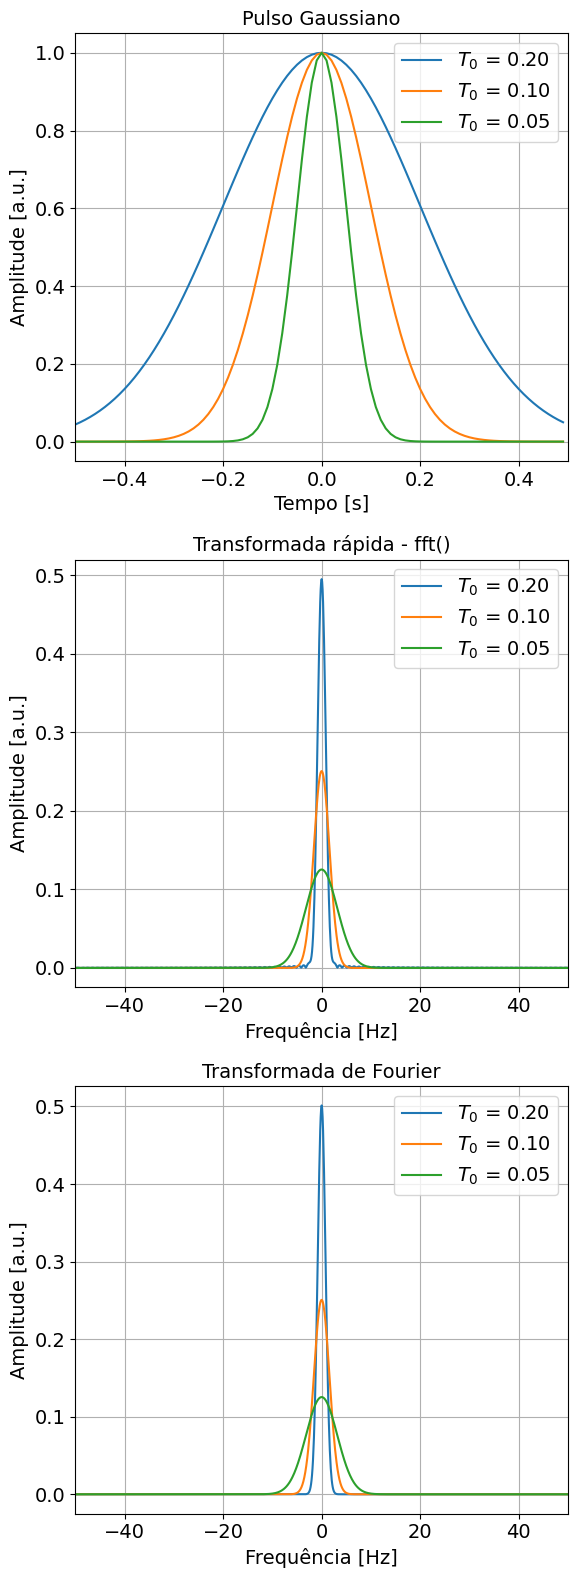

In [7]:
#Vẽ đồ thị mô phỏng và biến đổi Fourier
fig, axs = plt.subplots(3,1, figsize=(6,16)) # Tạo khung đồ thị gồm 3 đồ thị (3 hàng, 1 cột)
for i in range(len(T0)): # Vòng lặp duyệt qua từng giá trị T0
  x   = GaussPulse(A0, T0[i], t)             # Gaussian PulT0: # Tính tín hiệu thời gian cho T0 tương ứng
  axs[0].plot(t, x, label = r'$T_0$ = %3.2f' % (T0[i])) # Vẽ xung Gaussian thời gian lên đồ thị thứ 1 (axs[0])
  axs[0].set_xlabel('Tempo [s]') #đặt tên trục x
  axs[0].set_ylabel('Amplitude [a.u.]')    #đặt tên trục y 

  # Biến đổi FFT của tín hiệu x, dịch phổ tần số trung tâm về 0 bằng fftshift
  Xf  = np.fft.fftshift(np.fft.fft(x, NFFT)) # Pulse Fourier transform (fft)
    # Vẽ phổ FFT (chia cho L để chuẩn hóa) lên đồ thị thứ 2 (axs[1])
  axs[1].plot(f, abs(Xf)/L, label = r'$T_0$ = %3.2f' % (T0[i]))
  axs[1].set_xlabel('Frequência [Hz]')
  axs[1].set_ylabel('Amplitude [a.u.]')
  
  Xa  = FGaussPulse(A0, T0[i], f)            # Pulse Fourier transform (analytical)
    # Tính phổ Gaussian theo công thức lý thuyết (giải tích)
  axs[2].plot(f, Xa, label = r'$T_0$ = %3.2f' % (T0[i]))
  axs[2].set_xlabel('Frequência [Hz]')
  axs[2].set_ylabel('Amplitude [a.u.]')

axs[0].set_xlim([-0.5,0.5])
axs[0].legend()
axs[0].grid(True)
axs[0].set_title('Pulso Gaussiano')

axs[1].set_xlim([-fs/2,fs/2])
axs[1].legend()
axs[1].grid(True)
axs[1].set_title('Transformada rápida - fft()')

axs[2].set_xlim([-fs/2,fs/2])
axs[2].legend()
axs[2].grid(True)
axs[2].set_title('Transformada de Fourier')
plt.tight_layout()

## Super Gaussian Pulse

There are other pulse formats, for example, the super Gaussian pulse:
\begin{equation}
    A\left( 0,t \right) = A_0 e^{-\frac{1}{2}\left( \frac{t}{T_0} \right)^{2m}},
\end{equation}
where $m$ corresponds to the edge shape coefficient. For $m = 1$, the Gaussian pulse described previously is obtained. For high values ​​of $m$ the pulse has a shape close to rectangular.

In [8]:
#Định nghĩa hàm Xung Siêu Gaussian
def SuperGaussPulse(a0, t0, t, m):      # Super Gaussian pulse expression
  return a0*np.exp(-0.5*(t/t0)**(2*m))

In [9]:
T0 = 0.1
m  = np.array([1, 2, 10, 100])

Text(0.5, 1.0, 'Transformada rápida - fft()')

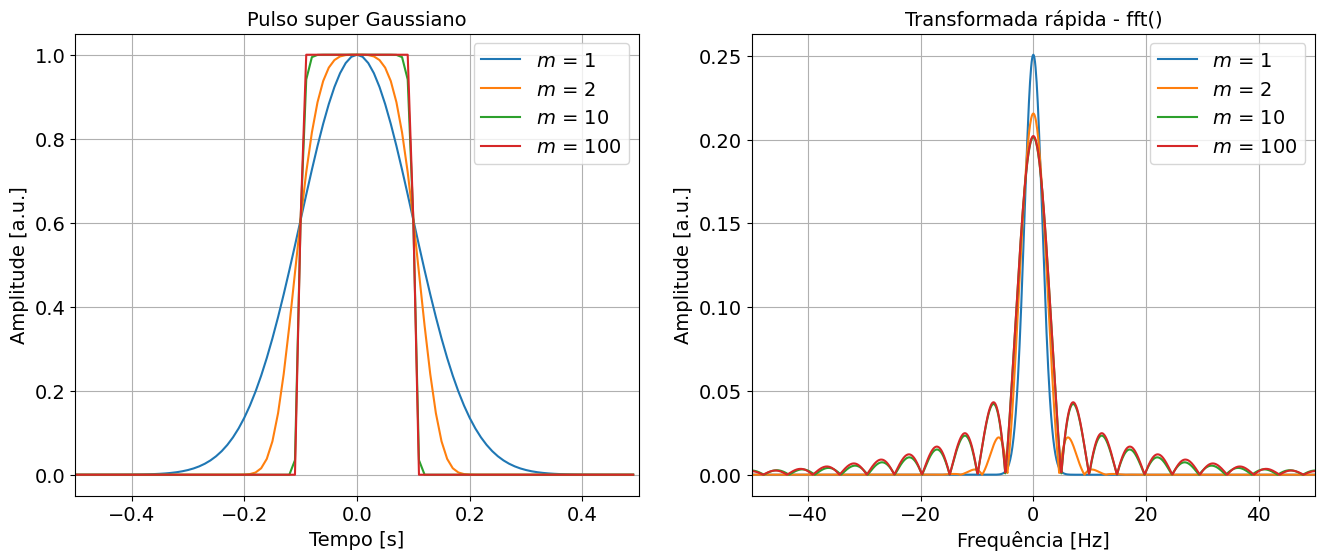

In [10]:
fig, axs = plt.subplots(1,2, figsize=(16,6))
for i in range(len(m)):
  x   = SuperGaussPulse(A0, T0, t, m[i])        # Super Gaussian pulse
  axs[0].plot(t, x, label = r'$m$ = %d' % (m[i]))
  axs[0].set_xlabel('Tempo [s]')
  axs[0].set_ylabel('Amplitude [a.u.]')
  Xf  = np.fft.fftshift(np.fft.fft(x, NFFT)) # Pulse Fourier transform (fft)
  axs[1].plot(f, abs(Xf)/L, label = r'$m$ = %d' % (m[i]))
  axs[1].set_xlabel('Frequência [Hz]')
  axs[1].set_ylabel('Amplitude [a.u.]')

axs[0].set_xlim([-0.5,0.5])
axs[0].legend()
axs[0].grid(True)
axs[0].set_title('Pulso super Gaussiano')

axs[1].set_xlim([-fs/2,fs/2])
axs[1].legend()
axs[1].grid(True)
axs[1].set_title('Transformada rápida - fft()')

# Basic propagation equation

The basic propagation equation, disregarding losses and non-linear effects, is:
\begin{equation}
\frac{\partial A}{\partial z} + i \frac{\beta_2}{2}\frac{\partial^2 A}{\partial t^2} - \frac{\beta_3}{6}\frac{\partial^3 A}{\partial t^3} = 0.
\end{equation}
We can also consider the third-order term of the expansion of the propagation constant:
\begin{equation}
\frac{\partial A}{\partial z} + i \frac{\beta_2}{2}\frac{\partial^2 A}{\partial t^2} = 0.
\end{equation}
The solution to this equation is obtained using the Fourier transform method:
\begin{equation}
\widetilde{A}\left(z, \omega \right) = \widetilde{A}\left(0, \omega \right) e^{j\frac{\beta_2}{2} \omega^2 z},
\end{equation}
where $\widetilde{A}\left(0, \omega \right)$ is the Fourier transform of the incident field at $z = 0$:
\begin{equation}
\widetilde{A}\left(0, \omega \right) = \int_{-\infty}^{\infty}A\left(0, t\right)e^{i \omega t} \text{d}t.
\end{equation}

In [11]:
fs = 256                        # Sampling rate
NFFT = 256                      # Number of transform points
t  = np.arange(-0.5,0.5,1/fs)   # Pulse window duration
L = len(t)                      # Time window length
f = fs/NFFT * np.arange(-NFFT/2,NFFT/2)
beta2 = 20e-6                   # GVD parameter
z = 250                         # propagation distance
T0 = 0.05                       # Half width parameter @1/e
A0 = 1                          # Pulse amplitude

Channel transfer function:

In [12]:
#Định nghĩa Hàm truyền Kênh truyền H(f)
H  = np.exp(1j*0.5*beta2*z*(2*np.pi*f)**2) # Channel transfer function

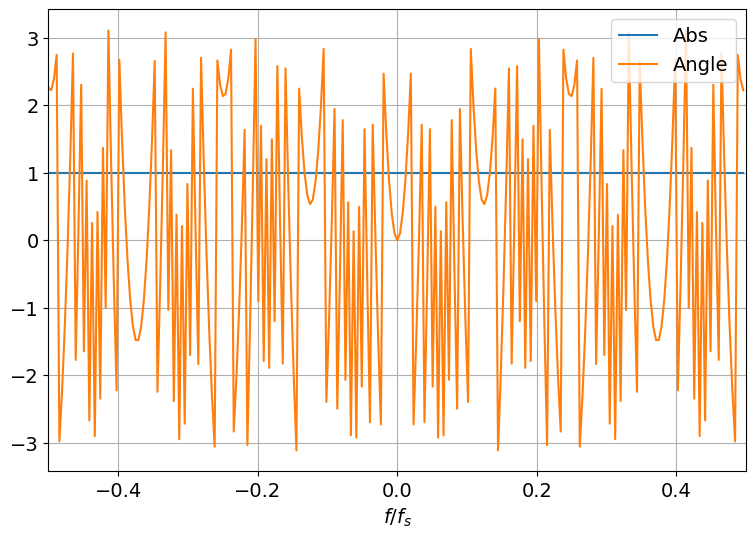

In [13]:
#Vẽ đặc tính Biên độ và Pha của Kênh truyền
fig = plt.figure(figsize=(9,6))
# plt.plot(f/fs, H.real, f/fs, H.imag)
plt.plot(f/fs, abs(H), f/fs, np.angle(H)) # Vẽ Biên độ abs(H) và Pha np.angle(H) theo tần số chuẩn hóa f/fs
plt.xlabel(r'$f/f_s$')
plt.xlim([-0.5,0.5])
# plt.legend(['Real', 'Imag'], loc = 'upper right')
plt.legend(['Abs', 'Angle'], loc = 'upper right')
plt.grid(True)

The generated pulse will be applied to the channel:

In [14]:
# T Domain
x  = GaussPulse(A0, T0, t)       # Gaussian Pulse
# F Domain
X  = FGaussPulse(A0, T0, f)      # Gaussian pulse Fourier transform (analytical)
XH = X*H                         # Resulting signal
# T Domain
xh  = np.fft.ifftshift(np.fft.ifft(XH)) # Inverse transform (ifft)
xhA = T0/np.sqrt(T0**2-1j*beta2*z) * np.exp(-(t**2)/(2*(T0**2-1j*beta2*z))) # Resulting signal (analytical expression)

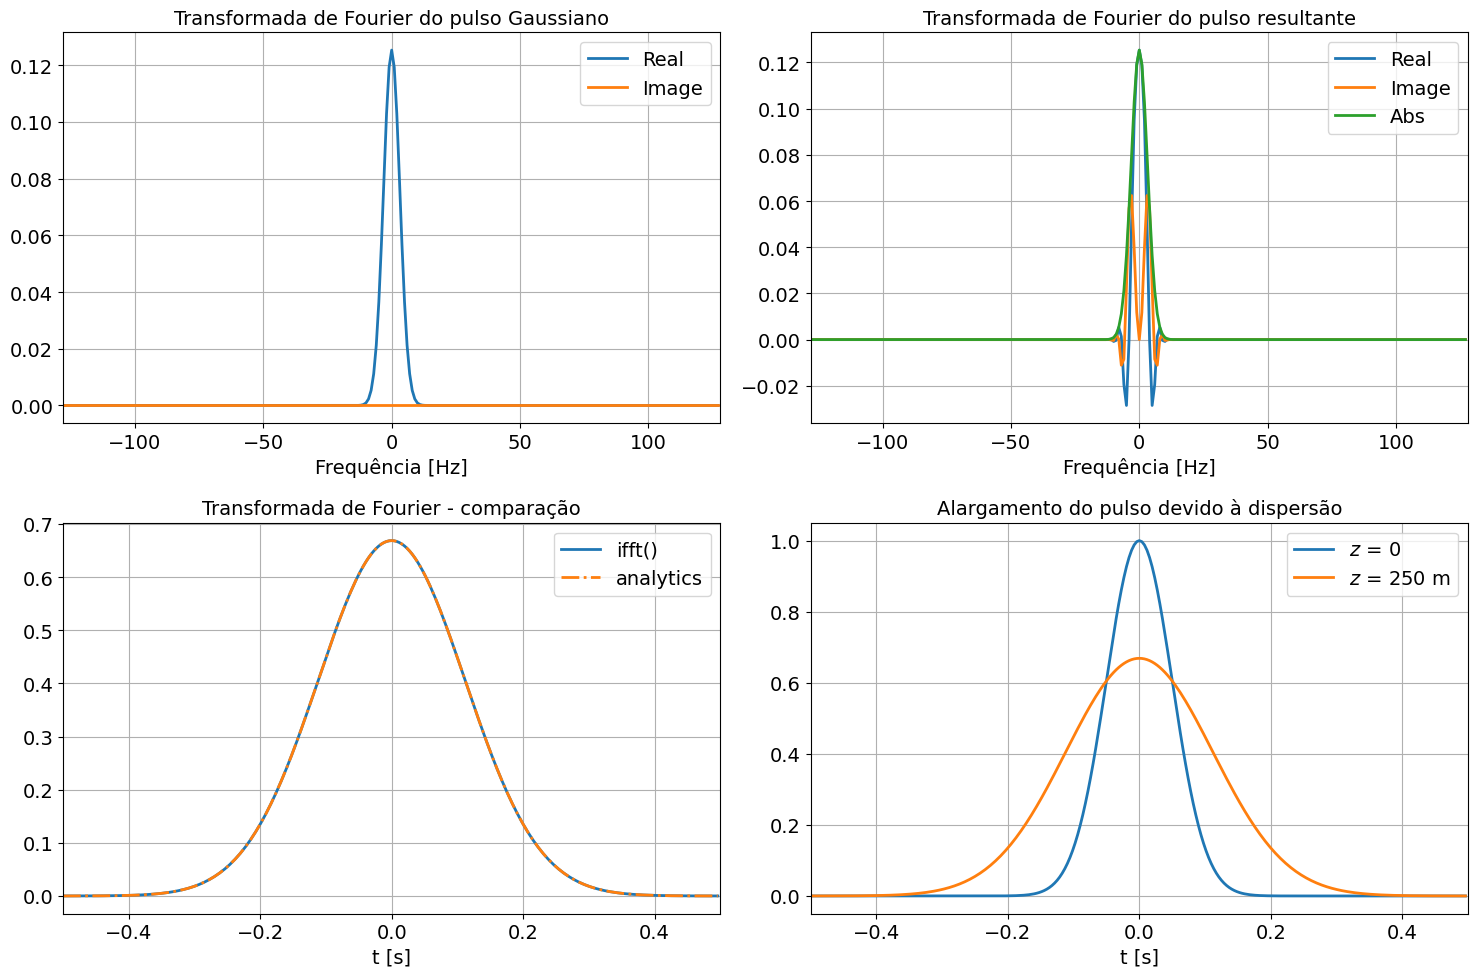

In [15]:
fig, axs = plt.subplots(2,2, figsize=(15,10))
axs[0,0].plot(f, X.real, label = 'Real', linewidth = 2)
axs[0,0].plot(f, X.imag, label = 'Image', linewidth = 2)
axs[0,0].set_xlabel('Frequência [Hz]')
axs[0,0].set_xlim([-fs/2,fs/2])
axs[0,0].set_title('Transformada de Fourier do pulso Gaussiano')
axs[0,0].grid(True)
axs[0,0].legend()

axs[0,1].plot(f, XH.real, label = 'Real', linewidth = 2)
axs[0,1].plot(f, XH.imag, label = 'Image', linewidth = 2)
axs[0,1].plot(f, np.abs(XH), label = 'Abs', linewidth = 2)
axs[0,1].set_xlabel('Frequência [Hz]')
axs[0,1].set_xlim([-fs/2,fs/2])
axs[0,1].set_title('Transformada de Fourier do pulso resultante')
axs[0,1].grid(True)
axs[0,1].legend()

axs[1,0].plot(t, np.abs(xh*L), label = 'ifft()', linewidth = 2)
axs[1,0].plot(t, np.abs(xhA), '-.', label = 'analytics', linewidth = 2)
axs[1,0].set_xlabel('t [s]')
axs[1,0].set_xlim([-0.5,0.5])
axs[1,0].set_title('Transformada de Fourier - comparação')
axs[1,0].grid(True)
axs[1,0].legend()

axs[1,1].plot(t, x, label = r'$z$ = 0', linewidth = 2)
axs[1,1].plot(t, np.abs(xhA), label = r'$z$ = %d m' %(z), linewidth = 2)
axs[1,1].set_xlabel('t [s]')
axs[1,1].set_xlim([-0.5,0.5])
axs[1,1].set_title('Alargamento do pulso devido à dispersão')
axs[1,1].grid(True)
axs[1,1].legend()

plt.tight_layout()

The pulse broadening factor is determined by
\begin{equation}
\frac{T_1(z)}{T_0} = \sqrt{1 + \left(\frac{z}{L_D}\right)^2}
\end{equation}
where $L_D = T_0^2 / \left|\beta_2\right|$ is the scattering length. At this length, the Gaussian pulse is $\sqrt{2}$ wider than the original.

In [16]:
LD = (T0**2)/abs(beta2)
print('Dispersion length [m]: %f' %(LD))

Dispersion length [m]: 125.000000


In [17]:
T1 = T0*np.sqrt(1+(z/LD)**2)
print("Pulse width after %f [m]: %f [s]" %(z, T1))
print("Flare factor: %f" %(T1/T0))

Pulse width after 250.000000 [m]: 0.111803 [s]
Flare factor: 2.236068


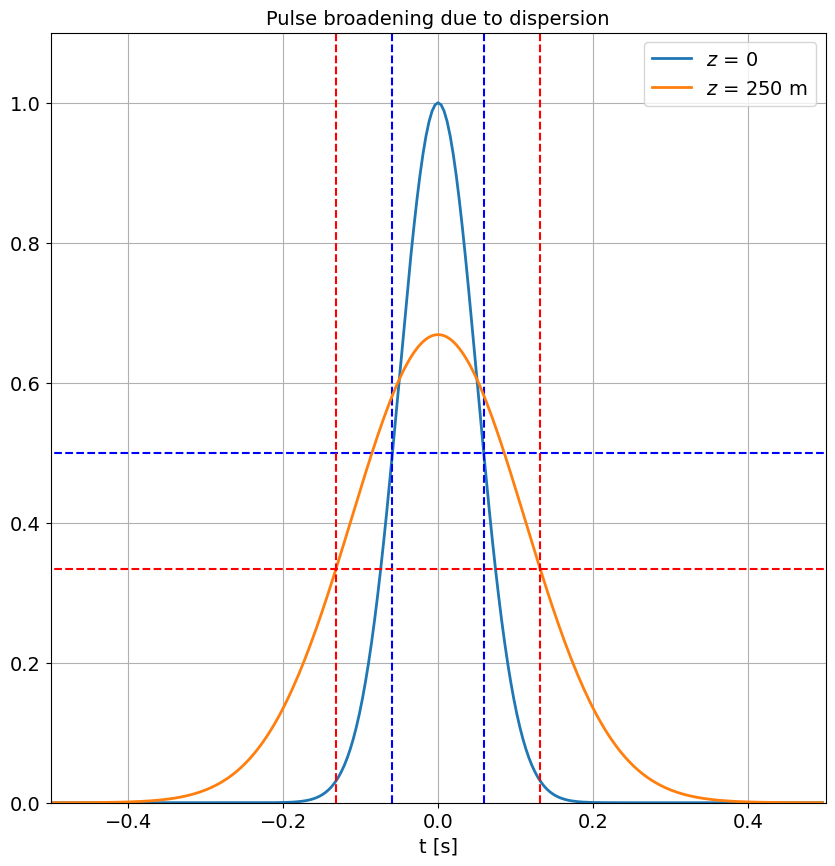

In [18]:
fig = plt.figure(figsize=(10,10))

plt.plot(t, x, label = r'$z$ = 0', linewidth = 2)
plt.plot([-1,1],[0.5,0.5], 'b--')
plt.plot([1.665*T0/np.sqrt(2),1.665*T0/np.sqrt(2)],[0,1.2], 'b--')
plt.plot([-1.665*T0/np.sqrt(2),-1.665*T0/np.sqrt(2)],[0,1.2], 'b--')

plt.plot(t, np.abs(xhA), label = r'$z$ = %d m' %(z), linewidth = 2)
maxxhA = max(np.abs(xhA))
plt.plot([-1,1],[0.5*maxxhA,0.5*maxxhA], 'r--')
plt.plot([1.665*T1/np.sqrt(2),1.665*T1/np.sqrt(2)],[0,1.2], 'r--')
plt.plot([-1.665*T1/np.sqrt(2),-1.665*T1/np.sqrt(2)],[0,1.2], 'r--')

plt.xlabel('t [s]')
plt.xlim([-0.5,0.5])
plt.ylim([0,1.1])
plt.title('Pulse broadening due to dispersion')
plt.grid(True)
plt.legend()

## "chirped" Gaussian pulse - *chirped Gaussian pulse*

When the carrier frequency varies with time in a Gaussian pulse, the pulse is said to *chirp*. The amplitude of this signal is
\begin{equation}
A\left( 0,t \right) = A_0e^{-\frac{\left(1+iC\right)}{2}\left( \frac{t}{T_0} \right)^2},
\end{equation}
where $C$ is the parameter that quantifies the pulse frequency variation related to the phase variation $\phi(t)$ per
\begin{equation}
  \delta\omega(t) = -\frac{\partial \phi}{\partial t} = \frac{C}{T_0^2}t.
\end{equation}
The phase variation $\delta\omega(t)$ is called *chirp*. The Fourier transform of the Gaussian pulse with *chirp* is
\begin{equation}
\widetilde{A}\left(0, \omega \right) = A_0\sqrt{\left( \frac{2\pi T_0^2}{1+iC} \right)} e^{-\frac{1}{2}\left[\frac{\left( \omega T_0\right)^2}{1+iC}\right]},
\end{equation}

Definition of "chirping" pulse expressions:

In [19]:
# Hàm tạo xung Gaussian có Chirp trong miền thời gian A(0,t)
def CGaussPulse(a0, t0, t, c):      # Gaussian pulse expression
  return a0*np.exp(-0.5*(1+1j*c)*(t/t0)**2)
# Hàm tính Phổ Fourier giải tích của xung Gaussian có Chirp
def CFGaussPulse(a0, t0, freq, c):  # Gaussian pulse Fourier transform (analytical)
  return a0*np.sqrt((2*np.pi*t0**2)/(1+1j*c))*np.exp(-0.5*((2*np.pi*freq*t0)**2)/(1+1j*c))

In [20]:
T0 = np.array([0.2, 0.1, 0.05]) # Half width parameter @1/e: Mảng chứa 3 giá trị độ rộng xung khác nhau (s)
A0 = 1                          # Pulse amplitude:Biên độ đỉnh ban đầu A_0 = 1
fs = 100                        # Sampling rate
NFFT = 1024                     # Number of transform points
t  = np.arange(-0.5,0.5,1/fs)   # Pulse window duration: thời gian từ -0.5s đến 0.5s
L = len(t)                      # Time window length
f = fs/NFFT * np.arange(-NFFT/2,NFFT/2) #tần số từ -fs/2 đến fs/2 với bước fs/NFFT
C = 2  # Hệ số Chirp cố định C = 2 (Up-chirp)

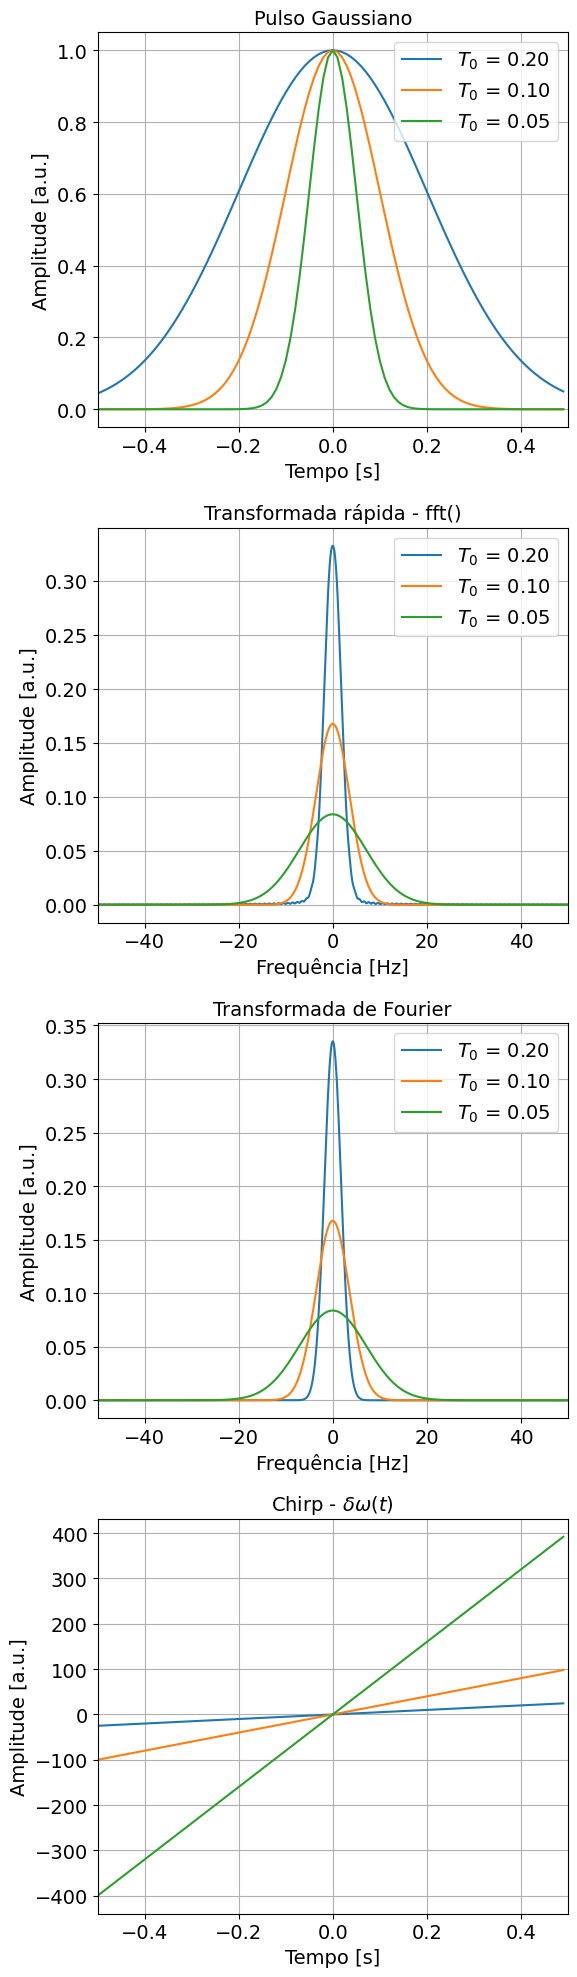

In [21]:
fig, axs = plt.subplots(4,1, figsize=(6,20))
for i in range(len(T0)):
  #Tạo xung thời gian cho từng T0[i] và vẽ lên axs[0]
  x   = CGaussPulse(A0, T0[i], t, C)         # Gaussian Pulse
  axs[0].plot(t, abs(x), label = r'$T_0$ = %3.2f' % (T0[i]))
  axs[0].set_xlabel('Tempo [s]')
  axs[0].set_ylabel('Amplitude [a.u.]')
  #Tính FFT số học, chuẩn hóa biên độ (/L) và vẽ lên axs[1]
  Xf  = np.fft.fftshift(np.fft.fft(x, NFFT)) # Pulse Fourier transform (fft)
  axs[1].plot(f, abs(Xf)/L, label = r'$T_0$ = %3.2f' % (T0[i]))
  axs[1].set_xlabel('Frequência [Hz]')
  axs[1].set_ylabel('Amplitude [a.u.]')
  #Tính Phổ giải tích (Analytical) và vẽ lên axs[2] để đối chiếu với FFT
  Xa  = CFGaussPulse(A0, T0[i], f, C)        # Pulse Fourier transform (analytical)
  axs[2].plot(f, abs(Xa), label = r'$T_0$ = %3.2f' % (T0[i]))
  axs[2].set_xlabel('Frequência [Hz]')
  axs[2].set_ylabel('Amplitude [a.u.]')
  #Tính độ lệch tần số tức thời dOmega = (C / T0^2) * t và vẽ lên axs[3]
  dOmega = t*C/(T0[i]**2)
  axs[3].plot(t, dOmega)
  axs[3].set_xlabel('Tempo [s]')
  axs[3].set_ylabel('Amplitude [a.u.]')

axs[0].set_xlim([-0.5,0.5])
axs[0].legend()
axs[0].grid(True)
axs[0].set_title('Pulso Gaussiano')

axs[1].set_xlim([-fs/2,fs/2])
axs[1].legend()
axs[1].grid(True)
axs[1].set_title('Transformada rápida - fft()')

axs[2].set_xlim([-fs/2,fs/2])
axs[2].legend()
axs[2].grid(True)
axs[2].set_title('Transformada de Fourier')
plt.tight_layout()

axs[3].set_xlim([-0.5,0.5])
axs[3].grid(True)
axs[3].set_title('Chirp - $\\delta \\omega(t)$')

plt.tight_layout()

Considering the dispersive channel with parameter GVD $\beta_2$, the resulting pulse is
\begin{equation}
A\left( z, t\right) = \frac{A_0}{\sqrt{Q(z)}}e^{-\frac{1}{2}\left[\frac{\left( 1+iC \right)}{Q(z)} \left(\frac{t}{T_0}\right)^2\right]},
\end{equation}
where $Q(z) = 1+(C-i)\beta_2 z/T_0^2$. The pulse is kept Gaussian, however, with altered width, amplitude and *chirp*.

In [22]:
T0 = 0.05                       # Half width parameter @1/e
A0 = 1                          # Pulse amplitude
fs = 256                        # Sampling rate
NFFT = 256                      # Number of transform points
beta2 = 20e-6                   # GVD parameter
z = 250                         # propagation distance
t  = np.arange(-0.5,0.5,1/fs)   # Pulse window duration
L = len(t)                      # Time window length
f = fs/NFFT * np.arange(-NFFT/2,NFFT/2)

Channel transfer function:

In [23]:
H  = np.exp(1j*0.5*beta2*z*(2*np.pi*f)**2) # Channel transfer function

The generated pulse will be applied to the channel:

In [24]:
# T Domain: Tạo xung chirp ban đầu tại z = 0
xC  = CGaussPulse(A0, T0, t, C)       # Gaussian Pulse
# F Domain: Tính phổ giải tích của xung ban đầu XC(f)
XC  = CFGaussPulse(A0, T0, f, C)      # Gaussian pulse Fourier transform (analytical)
XHC = XC*H                             # Resulting signal
# T Domain: Dùng IFFT để chuyển tín hiệu ngõ thu về miền thời gian (Số học)
xhC  = np.fft.ifftshift(np.fft.ifft(XHC)) # Inverse transform (ifft)
# T Domain: Tính tín hiệu ngõ thu theo công thức giải tích chuẩn xhAC(t)
Q = 1 + (C-1j)*beta2*z/T0**2  
xhAC = A0/np.sqrt(Q) * np.exp(-0.5*((1+1j*C)/Q)*(t/T0)**2) # Resulting signal (analytical expression)

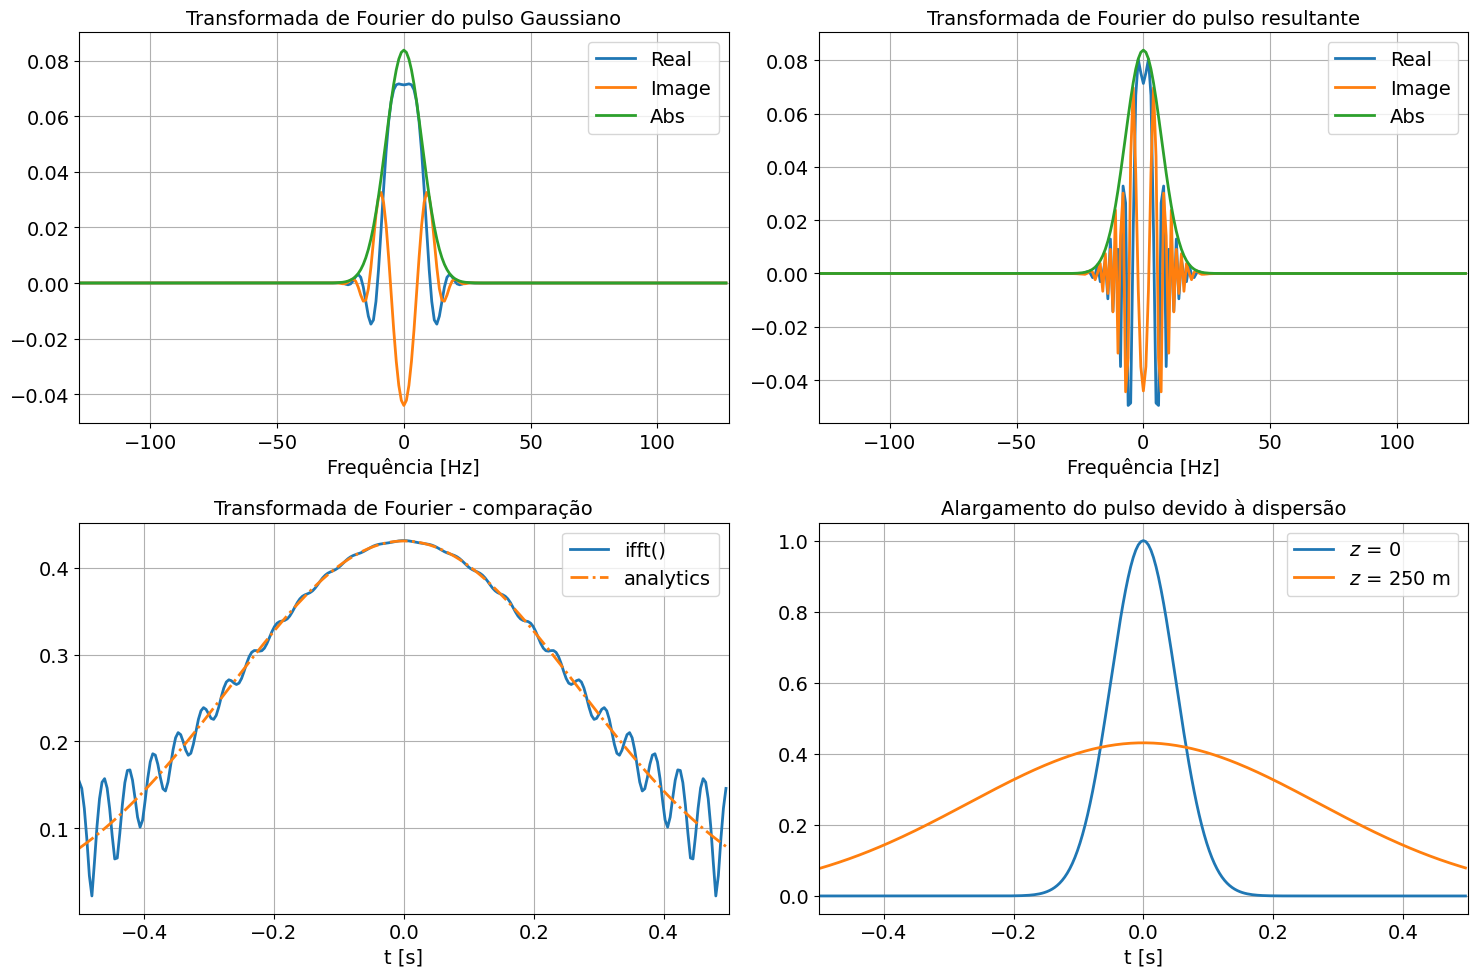

In [25]:
fig, axs = plt.subplots(2,2, figsize=(15,10))
axs[0,0].plot(f, XC.real, label = 'Real', linewidth = 2)
axs[0,0].plot(f, XC.imag, label = 'Image', linewidth = 2)
axs[0,0].plot(f, abs(XC), label = 'Abs', linewidth = 2)
axs[0,0].set_xlabel('Frequência [Hz]')
axs[0,0].set_xlim([-fs/2,fs/2])
axs[0,0].set_title('Transformada de Fourier do pulso Gaussiano')
axs[0,0].grid(True)
axs[0,0].legend()

axs[0,1].plot(f, XHC.real, label = 'Real', linewidth = 2)
axs[0,1].plot(f, XHC.imag, label = 'Image', linewidth = 2)
axs[0,1].plot(f, np.abs(XHC), label = 'Abs', linewidth = 2)
axs[0,1].set_xlabel('Frequência [Hz]')
axs[0,1].set_xlim([-fs/2,fs/2])
axs[0,1].set_title('Transformada de Fourier do pulso resultante')
axs[0,1].grid(True)
axs[0,1].legend()

axs[1,0].plot(t, abs(xhC*L), label = 'ifft()', linewidth = 2)
axs[1,0].plot(t, abs(xhAC), '-.', label = 'analytics', linewidth = 2)
axs[1,0].set_xlabel('t [s]')
axs[1,0].set_xlim([-0.5,0.5])
axs[1,0].set_title('Transformada de Fourier - comparação')
axs[1,0].grid(True)
axs[1,0].legend()

axs[1,1].plot(t, abs(xC), label = r'$z$ = 0', linewidth = 2)
axs[1,1].plot(t, abs(xhAC), label = r'$z$ = %d m' %(z), linewidth = 2)
axs[1,1].set_xlabel('t [s]')
axs[1,1].set_xlim([-0.5,0.5])
axs[1,1].set_title('Alargamento do pulso devido à dispersão')
axs[1,1].grid(True)
axs[1,1].legend()

plt.tight_layout()

The pulse widening factor in this case with chirping is determined by
\begin{equation}
\frac{T_1(z)}{T_0} = \sqrt{\left(1 + \frac{C\beta_2 z}{T_0^2}\right)^2 + \left(\frac{z}{L_D}\right)^2}
\end{equation}
where $C$ \'is the chirp coefficient.

In [26]:
LD = (T0**2)/abs(beta2)
print('Dispersion length [m]: %f' %(LD))

Dispersion length [m]: 125.000000


In [27]:
T1 = T0*np.sqrt((1+C*beta2*z/(T0**2))**2 + (z/LD)**2)
print("Pulse width after %f [m]: %f [s]" %(z, T1))
print("Flare factor: %f" %(T1/T0))

Pulse width after 250.000000 [m]: 0.269258 [s]
Flare factor: 5.385165


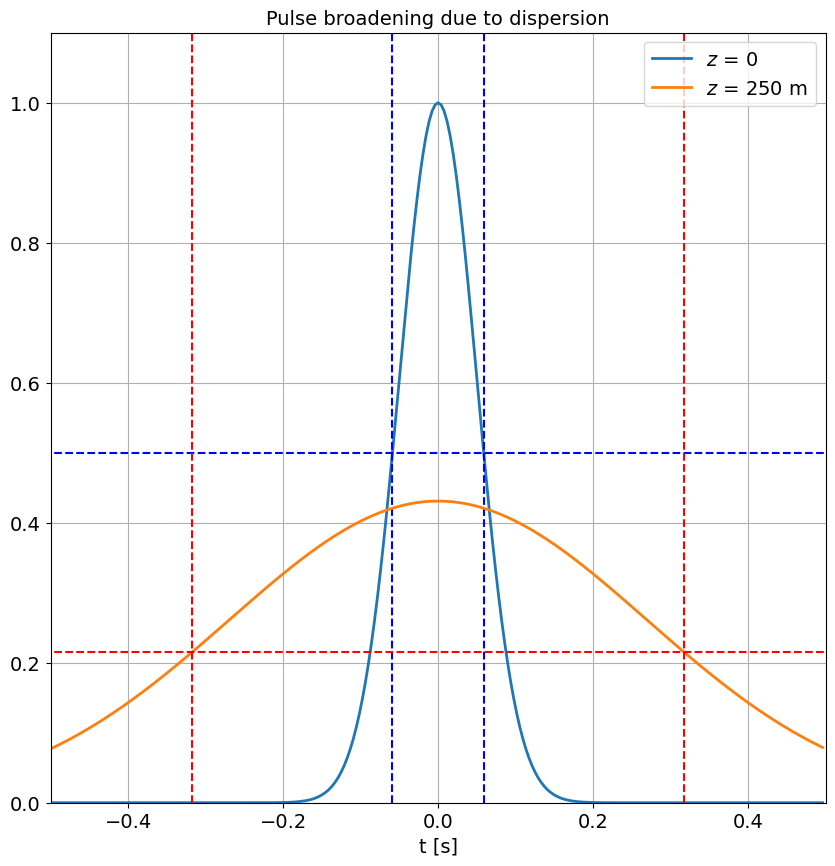

In [28]:
fig = plt.figure(figsize=(10,10))

plt.plot(t, abs(xC), label = r'$z$ = 0', linewidth = 2)
plt.plot([-1,1],[0.5,0.5], 'b--')
plt.plot([1.665*T0/np.sqrt(2),1.665*T0/np.sqrt(2)],[0,1.2], 'b--')
plt.plot([-1.665*T0/np.sqrt(2),-1.665*T0/np.sqrt(2)],[0,1.2], 'b--')

plt.plot(t, np.abs(xhAC), label = r'$z$ = %d m' %(z), linewidth = 2)
maxxhAC = max(np.abs(xhAC))
plt.plot([-1,1],[0.5*maxxhAC,0.5*maxxhAC], 'r--')
plt.plot([1.665*T1/np.sqrt(2),1.665*T1/np.sqrt(2)],[0,1.2], 'r--')
plt.plot([-1.665*T1/np.sqrt(2),-1.665*T1/np.sqrt(2)],[0,1.2], 'r--')

plt.xlabel('t [s]')
plt.xlim([-0.5,0.5])
plt.ylim([0,1.1])
plt.title('Pulse broadening due to dispersion')
plt.grid(True)
plt.legend()

## 10G OOK transmission with dispersion only

In [45]:
# simulation parameters
SpS = 32

Rs     = 10e9          # Symbol rate (for the case of OOK Rs = Rb)
Ts     = 1/Rs          # Symbol period in seconds
Fa     = 1/(Ts/SpS)    # Signal sampling frequency (samples/second)
Ta     = 1/Fa          # Sampling period

lmbd   = 1550e-9       # wave-length

Pi_dBm = 0             # optical signal power at modulator input in dBm

# MZM Parameters
Vπ = 2
Vb = -Vπ/2
Pi = 10**(Pi_dBm/10)*1e-3 # optical signal power in W at the MZM input

# Fiber parameters
D = 18e-6                        # Dispersion parameter ps/(nm*km) - SMF28
beta2 = -(D*lmbd**2)/(2*np.pi*c) # GVD
z = 10e3                         # Link length

# Receiver parameters
Rd  = 0.85      # A/W responsiveness

In [46]:
#Tính và in chiều dài tán sắc LD
LD = (Ts**2)/abs(beta2)
print('Dispersion length [m]: %f' %(LD))

Dispersion length [m]: 435576.729636


In [47]:
# generates sequence of pseudo-random bits: Tạo chuỗi bit ngẫu nhiên và dạng xung NRZ
bits   = np.random.randint(2, size=10000)    # Tạo 10,000 bit ngẫu nhiên 0 và 1
n      = np.arange(0, bits.size) 

# maps bits to electrical pulses
symbTx = 2*bits-1  ## Biến đổi bit [0,1] thành mức cực [-1, +1]
symbTx = symbTx/np.sqrt(signalPower(symbTx)) # Chuẩn hóa công suất tín hiệu

# upsampling
symbolsUp = upsample(symbTx, SpS)  #tăng mẫu tín hiệu bằng cách chèn thêm các giá trị 0 giữa các mẫu gốc

# typical NRZ pulse: # Tạo xung dạng NRZ bằng bộ lọc định hình xung
paramPS = parameters()
paramPS.pulseType = 'nrz'
paramPS.SpS = SpS
pulse = pulseShape(paramPS)
pulse = pulse/max(abs(pulse))

# signal plot
t = np.arange(0, symbTx.size)*(Ta/1e-9)

# idX = np.arange(0.513)
idX = np.arange(0,1023) # Cửa sổ hiển thị 1023 mẫu thời gian đầu tiên

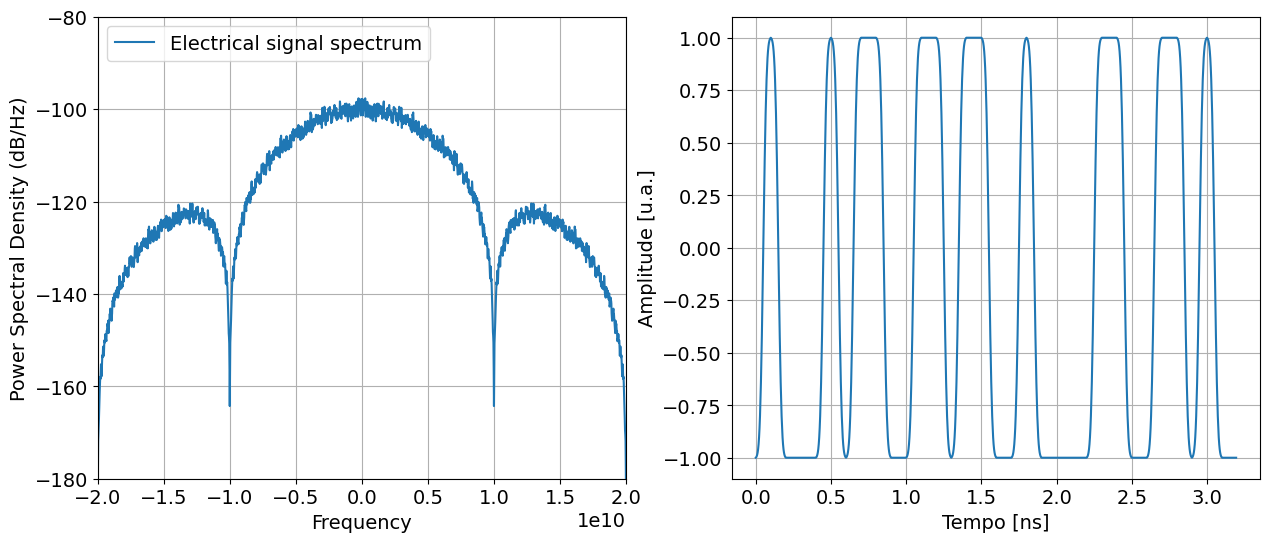

In [48]:
# pulse formatting
sigTx  = firFilter(pulse, symbolsUp) ## Lọc định hình xung NRZ cho chuỗi bit (Tín hiệu điện phát)

# psd plot: Đồ thị 1: Mật độ phổ công suất (PSD) của Tín hiệu Điện phát
fig, axs = plt.subplots(1, 2, figsize=(15,6))
axs[0].set_xlim(-2*Rs,2*Rs); # Giới hạn trục tần số từ -20 GHz đến +20 GHz
axs[0].set_ylim(-180,-80); # Trục tung biên độ dB/Hz
axs[0].psd(sigTx,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Electrical signal spectrum')
axs[0].legend(loc='upper left')
# Đồ thị 2: Dạng sóng tín hiệu điện phát trong miền thời gian (Time Domain)
axs[1].plot(t[idX], sigTx[idX].real)
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)

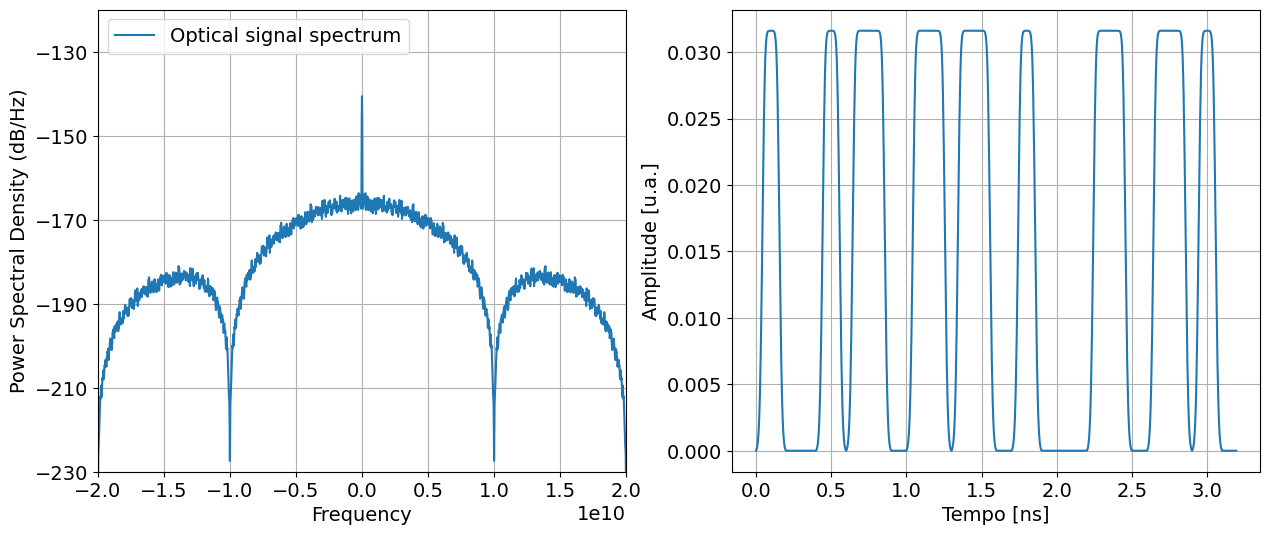

In [49]:
# optical modulation
Ai     = np.sqrt(Pi)
paramMZM = parameters()
paramMZM.Vpi = Vπ
paramMZM.Vb = Vb
sigTxo = mzm(Ai, sigTx, paramMZM)

# psd plot
fig, axs = plt.subplots(1, 2, figsize=(15,6))
axs[0].set_xlim(-2*Rs,2*Rs);
axs[0].set_ylim(-230,-120);
axs[0].psd(np.abs(sigTxo)**2,Fs=Fa, NFFT = 16*1024, sides='twosided', label = 'Optical signal spectrum')
axs[0].legend(loc='upper left')

axs[1].plot(t[idX], np.abs(sigTxo[idX]))
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)

In [50]:
# Biến đổi Fourier tín hiệu quang phát (sigTxo)
# optical transmission
NFFT = len(sigTxo)
sigTxoFFT = np.fft.fftshift(np.fft.fft(sigTxo))/NFFT # Biến đổi FFT và chuẩn hóa theo NFFT
sigTxoPx  = np.abs(sigTxoFFT)**2 # Mật độ phổ công suất phát (W)
freq = np.fft.fftshift(np.fft.fftfreq(len(sigTxoFFT), Ta))

# Mô hình hóa Kênh truyền Sợi quang (Optical fiber)
# Optical fiber
H  = np.exp(1j*0.5*beta2*z*(2*np.pi*freq)**2) # Channel transfer function
sigRxoFFT = H * sigTxoFFT # Phổ tín hiệu quang ngõ thu
sigRxoPx  = np.abs(sigRxoFFT)**2 # Mật độ phổ công suất thu (W)
sigRxo = np.fft.ifft(sigRxoFFT)*NFFT # Tín hiệu quang ngõ thu trong miền thời gian

Signal strength (in dBm) = -2.99 dBm


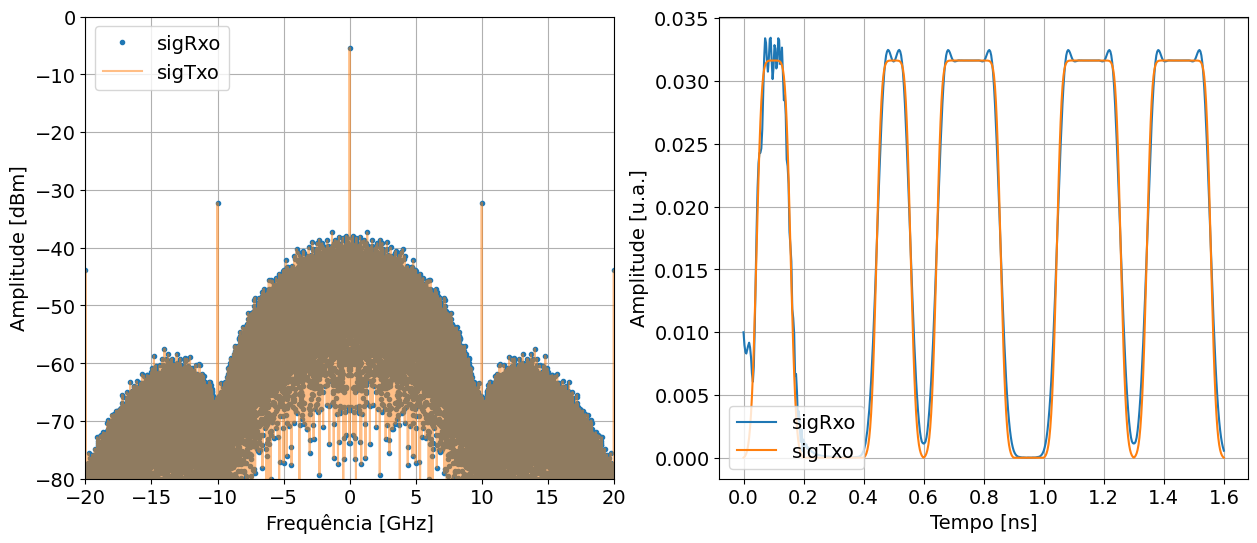

In [51]:
# Subplot 1: So sánh Phổ Biên độ Quang (dBm) giữa Phát (sigTxo) và Thu (sigRxo)
fig, axs = plt.subplots(1, 2, figsize=(15,6))
axs[0].plot(1e-9*freq, 10*np.log10(1e3*sigRxoPx), '.', label = 'sigRxo')
axs[0].plot(1e-9*freq, 10*np.log10(1e3*sigTxoPx), alpha = 0.5, label = 'sigTxo')
axs[0].set_ylabel('Amplitude [dBm]')
axs[0].set_xlabel('Frequência [GHz]')
axs[0].set_xlim(-2e-9*Rs,2e-9*Rs)
axs[0].set_ylim(-80,0)
axs[0].grid(True)
axs[0].legend(loc = 'upper left')

# Subplot 2: So sánh Dạng sóng Bao biên độ Quang (Time Domain) 513 mẫu đầu
axs[1].plot(t[0:513], abs(sigRxo[0:513]), label = 'sigRxo')
axs[1].plot(t[0:513], abs(sigTxo[0:513]), label = 'sigTxo')
axs[1].set_xlabel('Tempo [ns]')
axs[1].set_ylabel('Amplitude [u.a.]')
axs[1].grid(True)
axs[1].legend(loc = 'lower left')

print('Signal strength (in dBm) = %.2f dBm' %(10*np.log10(np.sum(sigTxoPx)/1e-3)))

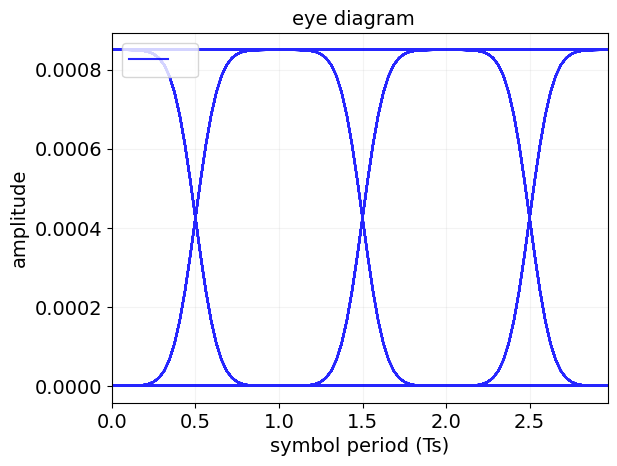

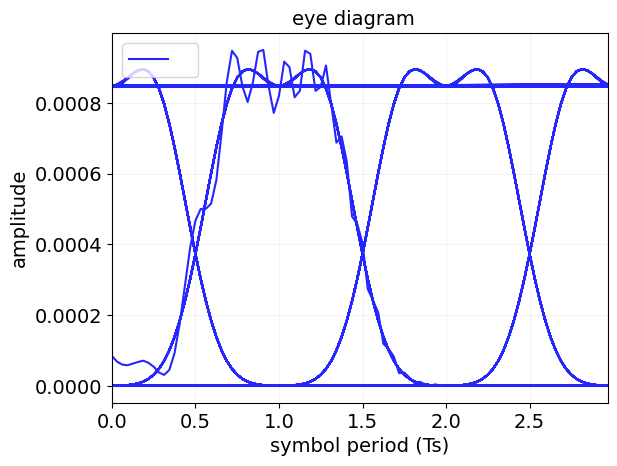

In [52]:
# Optical signal reception: Tách sóng tín hiệu quang
Nsamples = 2**12 # Số mẫu tín hiệu quang ngõ thu để hiển thị dạng sóng và biểu đồ mắt (4096 mẫu)

# noise free photocurrent: Dòng điện quang thu được (Photocurrent) không tính đến nhiễu (noise-free):I = Rd * P_opt = Rd * |E|^2
Ip   = Rd*np.abs(sigTxo)**2 # Dòng điện quang tại ngõ phát (chuẩn hóa z = 0 km)
I_Rx = Rd*np.abs(sigRxo)**2 # Dòng điện quang tại ngõ thu (sau z = 70 km sợi quang)

# eye diagram: Hiển thị biểu đồ mắt (Eye Diagram)
eyediagram(Ip,  Nsamples, SpS) # Biểu đồ mắt tín hiệu phát (Ip)
eyediagram(I_Rx, Nsamples, SpS) # Biểu đồ mắt tín hiệu thu (I_Rx)